####TomekLinks for removing overlapping in data
TomekLinks is more or less automatic tool, no parameters to adjust.

In [4]:
import os

print(os.getcwd())

c:\Users\Gayani\Advanced Data Analytics\AdvancedDataAnalytics\Exercise 2\task3_overlap_management


In [5]:
import pandas as pd

df = pd.read_csv("../HeartDisease_cleaned.csv")
df

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST
0,40,1,140,289,0,172,0,0.0,3,0,0,1,0,0,0,1,0
1,49,0,160,180,0,156,0,1.0,2,1,0,0,1,0,0,1,0
2,37,1,130,283,0,98,0,0.0,3,0,0,1,0,0,0,0,1
3,48,0,138,214,0,108,1,1.5,2,1,1,0,0,0,0,1,0
4,54,1,150,195,0,122,0,0.0,3,0,0,0,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
913,45,1,110,264,0,132,0,1.2,2,1,0,0,0,1,0,1,0
914,68,1,144,193,1,141,0,3.4,2,1,1,0,0,0,0,1,0
915,57,1,130,131,0,115,1,1.2,2,1,1,0,0,0,0,1,0
916,57,0,130,236,0,174,0,0.0,2,1,0,1,0,0,1,0,0


<Axes: >

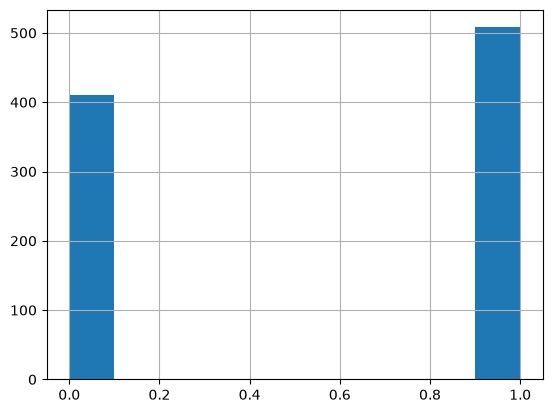

In [6]:
df['HeartDisease'].hist()

In [9]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="HeartDisease", axis=1)
y = df["HeartDisease"]

strategy = {
  
    1: 410
}

cc = ClusterCentroids(
    sampling_strategy=strategy,
    # random_state=31555
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["HeartDisease"] = y_resampled
df_resampled

,Age,Sex,RestingBP,Cholesterol,FastingBS,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_LVH,RestingECG_Normal,RestingECG_ST,HeartDisease
0,40,1,140,289,0,172,0,0.00,3,0,1,0,0,0,1,0,0
1,37,1,130,283,0,98,0,0.00,3,0,1,0,0,0,0,1,0
2,54,1,150,195,0,122,0,0.00,3,0,0,1,0,0,1,0,0
3,39,1,120,339,0,170,0,0.00,3,0,0,1,0,0,1,0,0
4,45,0,130,237,0,170,0,0.00,3,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
815,65,1,160,0,1,122,0,1.20,2,1,0,0,0,0,0,1,1
816,56,1,120,0,0,148,0,0.00,2,1,0,0,0,0,0,1,1
817,61,1,146,241,0,148,1,3.00,1,1,0,0,0,0,1,0,1
818,58,1,160,0,0,98,1,1.25,2,1,0,0,0,0,0,0,1


ValueError: Could not interpret value `alcohol` for `x`. An entry with this name does not appear in `data`.

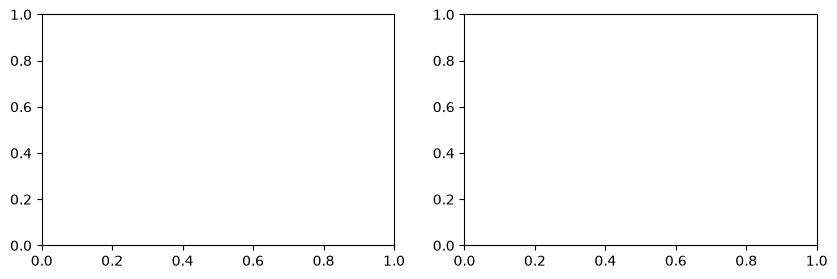

In [11]:
# boxplot version
import seaborn as sns
import matplotlib.pyplot as plt
# Let's look at it again. How did it perform?
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

sns.scatterplot(df_resampled, x="alcohol", y='volatile acidity', hue="quality", ax=axes[0])
sns.scatterplot(df, x="alcohol", y='volatile acidity', hue="quality", ax=axes[1])    
# Not bad too, but still a little underwhelming.

axes[0].set_title("Resampled Data")
axes[1].set_title("Original Data")

# more aggressive result this time
# still, lots of overlap in the qualities 5 and 6 in the data

<Axes: >

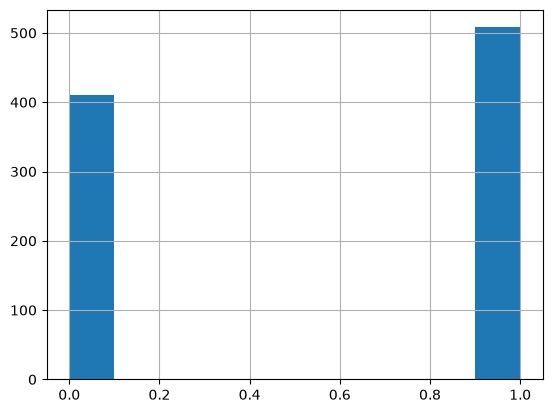

In [12]:
df['HeartDisease'].hist()

In [ ]:
from imblearn.under_sampling import ClusterCentroids

# X y split to prevent data leakage
X = df.drop(columns="quality", axis=1)
y = df["quality"]

strategy = {
    3: 10,
    4: 32,
    5: 400,
    6: 400,
    7: 166,
    8: 10
}

cc = ClusterCentroids(
    sampling_strategy=strategy,
    # random_state=31555
)

X_resampled, y_resampled = cc.fit_resample(X, y)

# Make a new copy (so we don't have trouble with dependency)
df_resampled = X_resampled.copy()

# Add y back into the X rows
df_resampled["quality"] = y_resampled
df_resampled